# Tendências por ano e fornecedores de LLM

Gera três figuras no estilo dos gráficos gerais (paleta verde-azulada de `../scripts/paleta.py`, barras com borda preta, séries de linha distinguidas também por marcador e tracejado):

- `jss_vendors`: % dos estudos de cada ano que usam cada fornecedor de LLM;
- `jss_trends`: % dos estudos de cada ano com cada prática (dois ou mais estágios, prompting iterativo, zero-shot, multiagente, fine-tuning);
- `jss_code_purpose_loop`: propósito do código de teste gerado × como o loop de revisão/reparo é fechado.

Os dados são contagens de estudos por ano calculadas em `dados_jss.py` a partir de `../data/tabela_de_codigos.csv` e `../data/tabela_de_codigos_artefatos.csv`; as porcentagens são calculadas sobre os estudos de cada ano. A série *Multi-agent* não conta os estudos com a coluna `Architecture` vazia.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ---------------------------------------------------------------------------
# Paleta: rampa em tons de verde-azulado, interpolada no espaço CIELAB para que
# o salto de claridade percebida entre tons vizinhos seja sempre o mesmo.
# A ponta clara é #eef5f6; a ponta escura é o #0b5a63 escurecido (mesmo matiz),
# o que aumenta a diferença entre os tons. Para voltar à rampa original,
# use ESCURECER = 0.
# ---------------------------------------------------------------------------
COR_ESCURA, COR_CLARA = "#0b5a63", "#eef5f6"
ESCURECER = 20          # quantos pontos de L* a ponta escura fica abaixo de #0b5a63

_M = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
_WN = np.array([0.95047, 1.0, 1.08883])
_D = 6 / 29

def _hex_para_lab(h):
    rgb = np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    t = (_M @ lin) / _WN
    f = np.where(t > _D ** 3, np.cbrt(t), t / (3 * _D ** 2) + 4 / 29)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])

def _lab_para_hex(lab):
    L, a, b = lab
    fy = (L + 16) / 116
    f = np.array([fy + a / 500, fy, fy - b / 200])
    xyz = np.where(f > _D, f ** 3, 3 * _D ** 2 * (f - 4 / 29)) * _WN
    lin = np.clip(np.linalg.solve(_M, xyz), 0, 1)
    rgb = np.where(lin <= 0.0031308, 12.92 * lin, 1.055 * lin ** (1 / 2.4) - 0.055)
    return "#" + "".join(f"{int(round(v * 255)):02x}" for v in rgb)

_LAB_CLARA = _hex_para_lab(COR_CLARA)
_LAB_ESCURA = _hex_para_lab(COR_ESCURA)
_LAB_ESCURA[0] -= ESCURECER          # mesma cor, menos claridade

def tons(n, inicio=0.0, fim=1.0):
    """n cores da rampa, da mais escura (fim) para a mais clara (inicio); 0 = #eef5f6."""
    return [_lab_para_hex(_LAB_CLARA + (_LAB_ESCURA - _LAB_CLARA) * t)
            for t in np.linspace(fim, inicio, n)]

# barras: rampa inteira, inclusive o tom quase branco (a borda preta o mantém visível)
CINZAS = tons(6)
# linhas: o tom quase branco sumiria no fundo, então as linhas param em 20% da rampa
CINZAS_LINHA = tons(6, inicio=0.20)
MARCADORES = ["o", "s", "^", "D", "v", "P"]
TRACOS = ["-", "--", "-.", ":", (0, (6, 2, 1, 2, 1, 2)), (0, (10, 3))]
COR_VALOR = "black"

# anos e estudos por ano, lidos de ../data/tabela_de_codigos.csv
from dados_jss import ANOS, ESTUDOS_POR_ANO, fornecedores, tendencias, caminhos, propositos, SEM_ARQUITETURA
print(dict(zip(ANOS, ESTUDOS_POR_ANO.tolist())))

def estilo_atividades(ax, ylabel):
    """Eixos no estilo de grafico_atividades.ipynb."""
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color("black")
    ax.tick_params(axis="x", length=5, pad=8, color="black", labelsize=11.5)
    ax.tick_params(axis="y", colors="#555555", labelsize=11)
    ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
    ax.set_axisbelow(True)
    ax.set_ylabel(ylabel, fontsize=12.5)

def rotulos_sem_sobreposicao(valores, espaco):
    """{nome: y_final} -> {nome: y_do_rotulo}, empurrando para cima rótulos muito próximos."""
    ordem = sorted(valores, key=lambda n: (valores[n], list(valores).index(n)))
    pos, ultimo = {}, -np.inf
    for n in ordem:
        pos[n] = max(valores[n], ultimo + espaco)
        ultimo = pos[n]
    return pos

def grafico_linhas(series, ylabel, ylim, rotulo_final, espaco_rotulos, xmax_extra, cores=None):
    """series: {nome: contagens por ano}. Plota % dos estudos de cada ano.
    cores: lista de cores por série (padrão: CINZAS_LINHA, da mais escura para a mais clara)."""
    cores = cores or CINZAS_LINHA
    fig, ax = plt.subplots(figsize=(11, 7), dpi=200)
    finais = {}
    for i, (nome, cont) in enumerate(series.items()):
        pct = np.array(cont) / ESTUDOS_POR_ANO * 100
        ax.plot(ANOS, pct, color=cores[i], linestyle=TRACOS[i], linewidth=2.4,
                zorder=3, clip_on=False)
        ax.scatter(ANOS, pct, s=95, marker=MARCADORES[i], color=cores[i],
                   edgecolor="black", linewidth=1.2, zorder=4, clip_on=False)
        finais[nome] = pct[-1]
    for nome, y in rotulos_sem_sobreposicao(finais, espaco_rotulos).items():
        ax.text(ANOS[-1] + 0.12, y, rotulo_final(nome, finais[nome]), va="center",
                fontsize=11.5, fontweight="bold", color=COR_VALOR)

    ax.set_xticks(ANOS)
    ax.set_xlim(ANOS[0] - 0.3, ANOS[-1] + xmax_extra)
    ax.set_ylim(*ylim)
    estilo_atividades(ax, ylabel)

    handles = [
        Line2D([0], [0], color=cores[i], linestyle=TRACOS[i], linewidth=2.4,
               marker=MARCADORES[i], markersize=9, markerfacecolor=cores[i],
               markeredgecolor="black", label=nome)
        for i, nome in enumerate(series)
    ]
    ax.legend(handles=handles, loc="upper center", frameon=False, fontsize=10.5,
              ncol=3, handlelength=3.2, bbox_to_anchor=(0.5, 1.0))
    return fig, ax

{2023: 26, 2024: 90, 2025: 240, 2026: 145}


## Fornecedores de LLM por ano — `images/jss_vendors.pdf`

{'OpenAI': 374, 'Meta': 160, 'DeepSeek': 102, 'Google': 83, 'Alibaba (Qwen)': 64, 'Anthropic': 59}


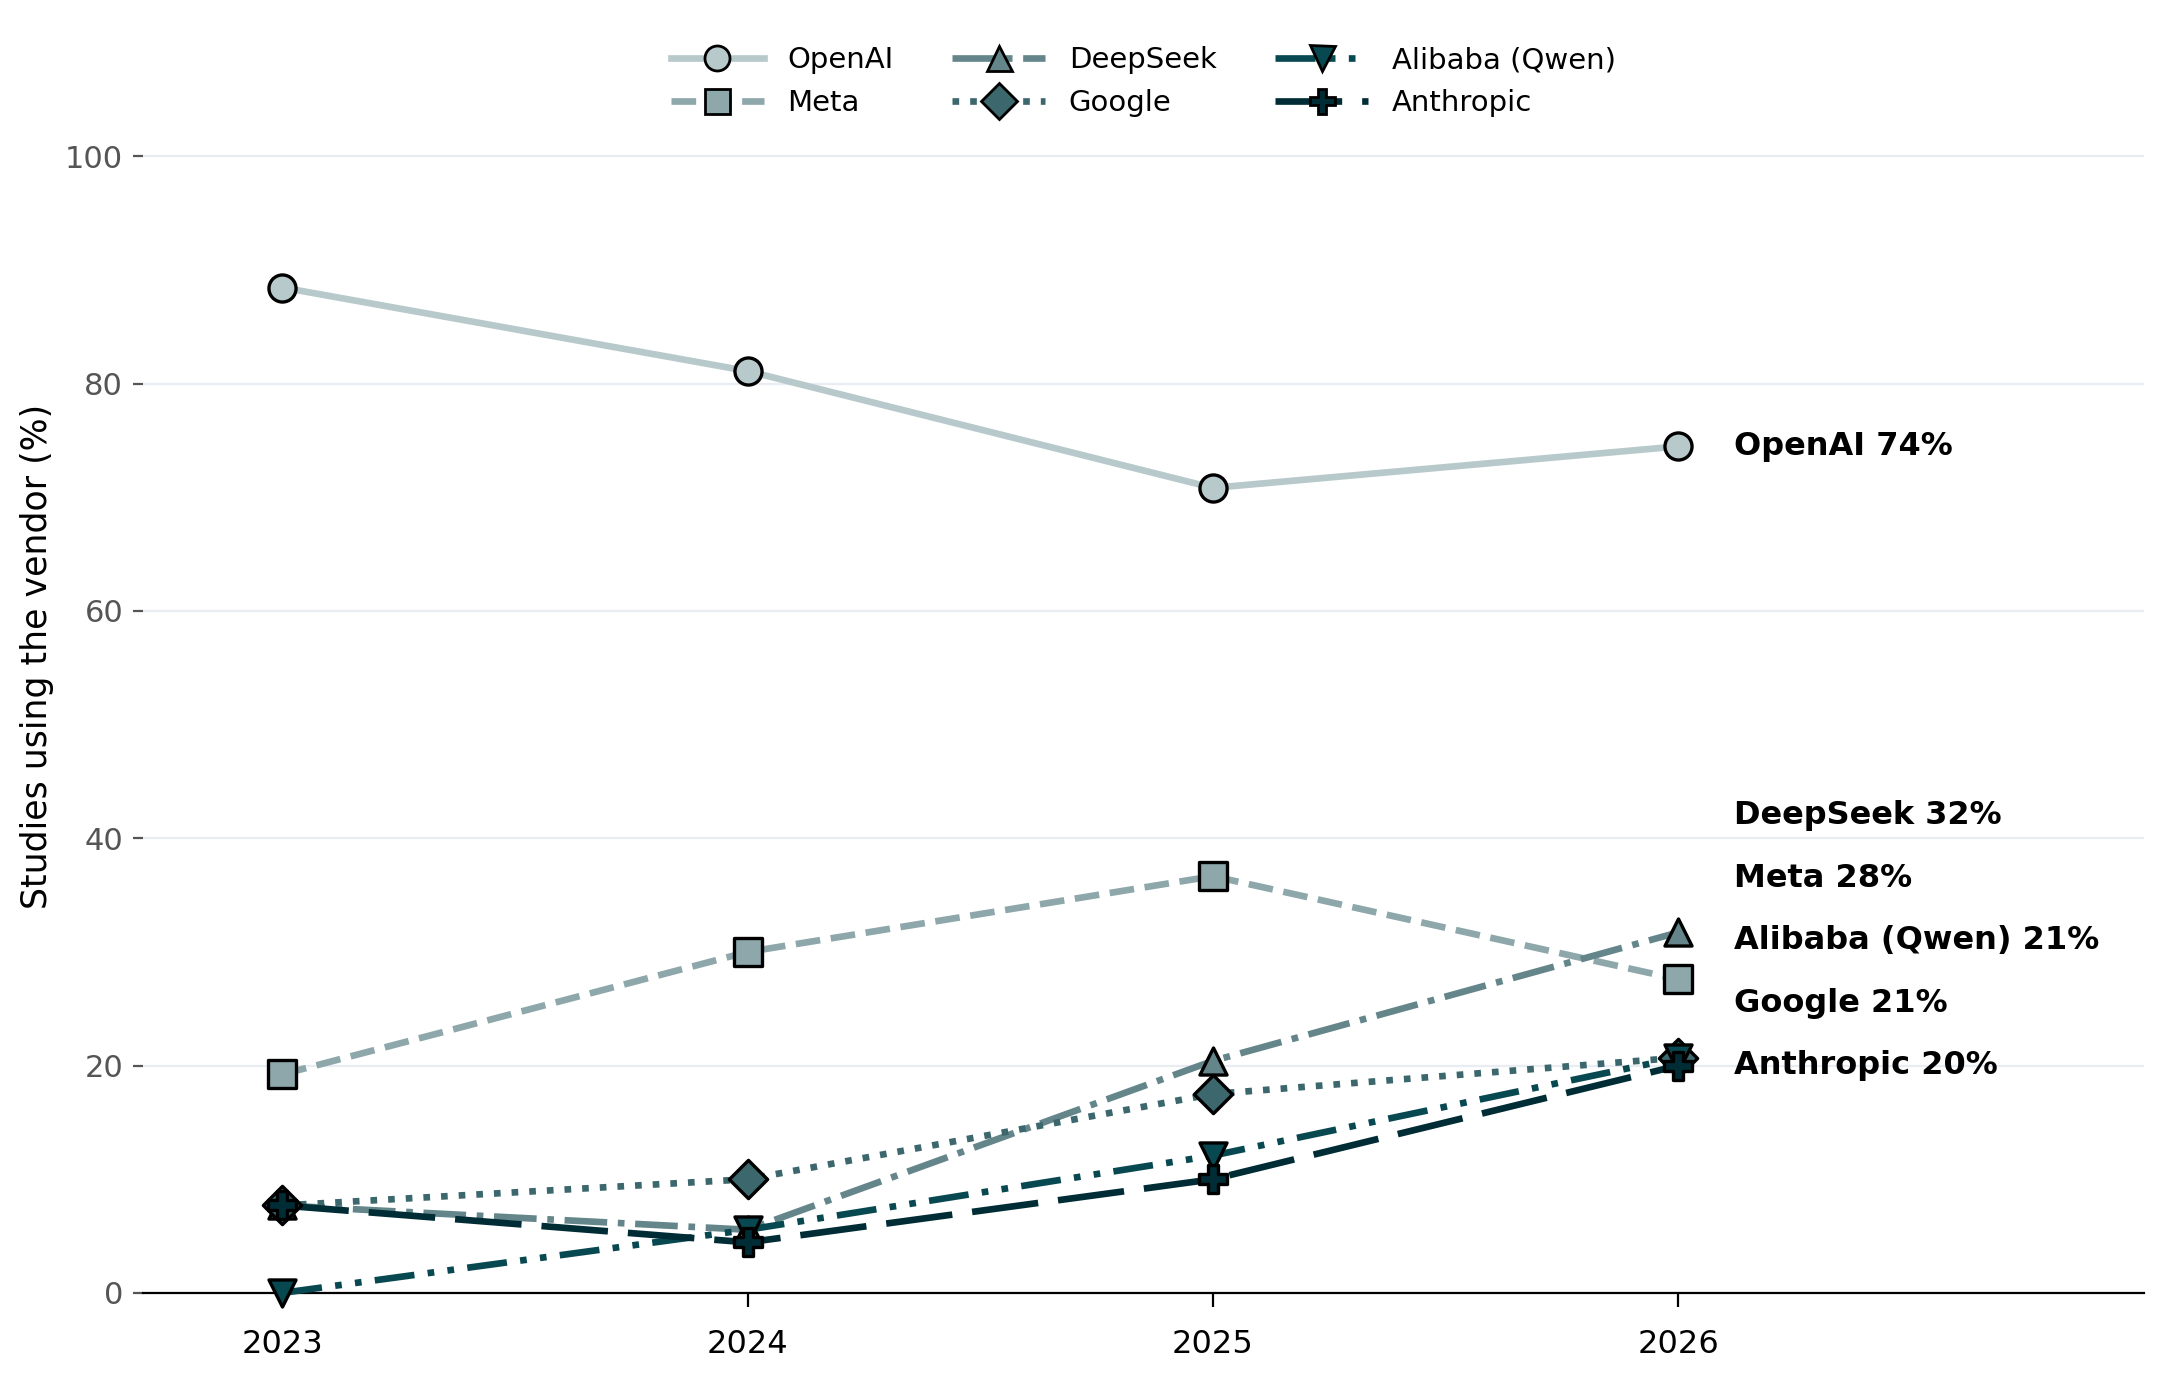

In [2]:
# estudos que usam cada fornecedor, por ano (dados_jss.fornecedores)
print({k: sum(v) for k, v in fornecedores.items()})

fig, ax = grafico_linhas(
    fornecedores,
    ylabel="Studies using the vendor (%)",
    ylim=(0, 112),
    rotulo_final=lambda nome, pct: f"{nome} {pct:.0f}%",
    espaco_rotulos=5.5,
    xmax_extra=1.0,
    cores=CINZAS_LINHA[::-1],   # começa pela cor mais clara
)
ax.set_yticks(range(0, 101, 20))

plt.tight_layout()
plt.savefig("jss_vendors.pdf", bbox_inches="tight")
plt.savefig("jss_vendors.png", bbox_inches="tight", dpi=200)
plt.show()

## Tendências das técnicas por ano — `images/jss_trends.pdf`

{'Two or more stages': 199, 'Iterative prompting': 179, 'Zero-shot prompting': 188, 'Multi-agent': 58, 'Fine-tuning': 54}
Multi-agent: a coluna Architecture está vazia em 111 estudos, que não contam como multiagente


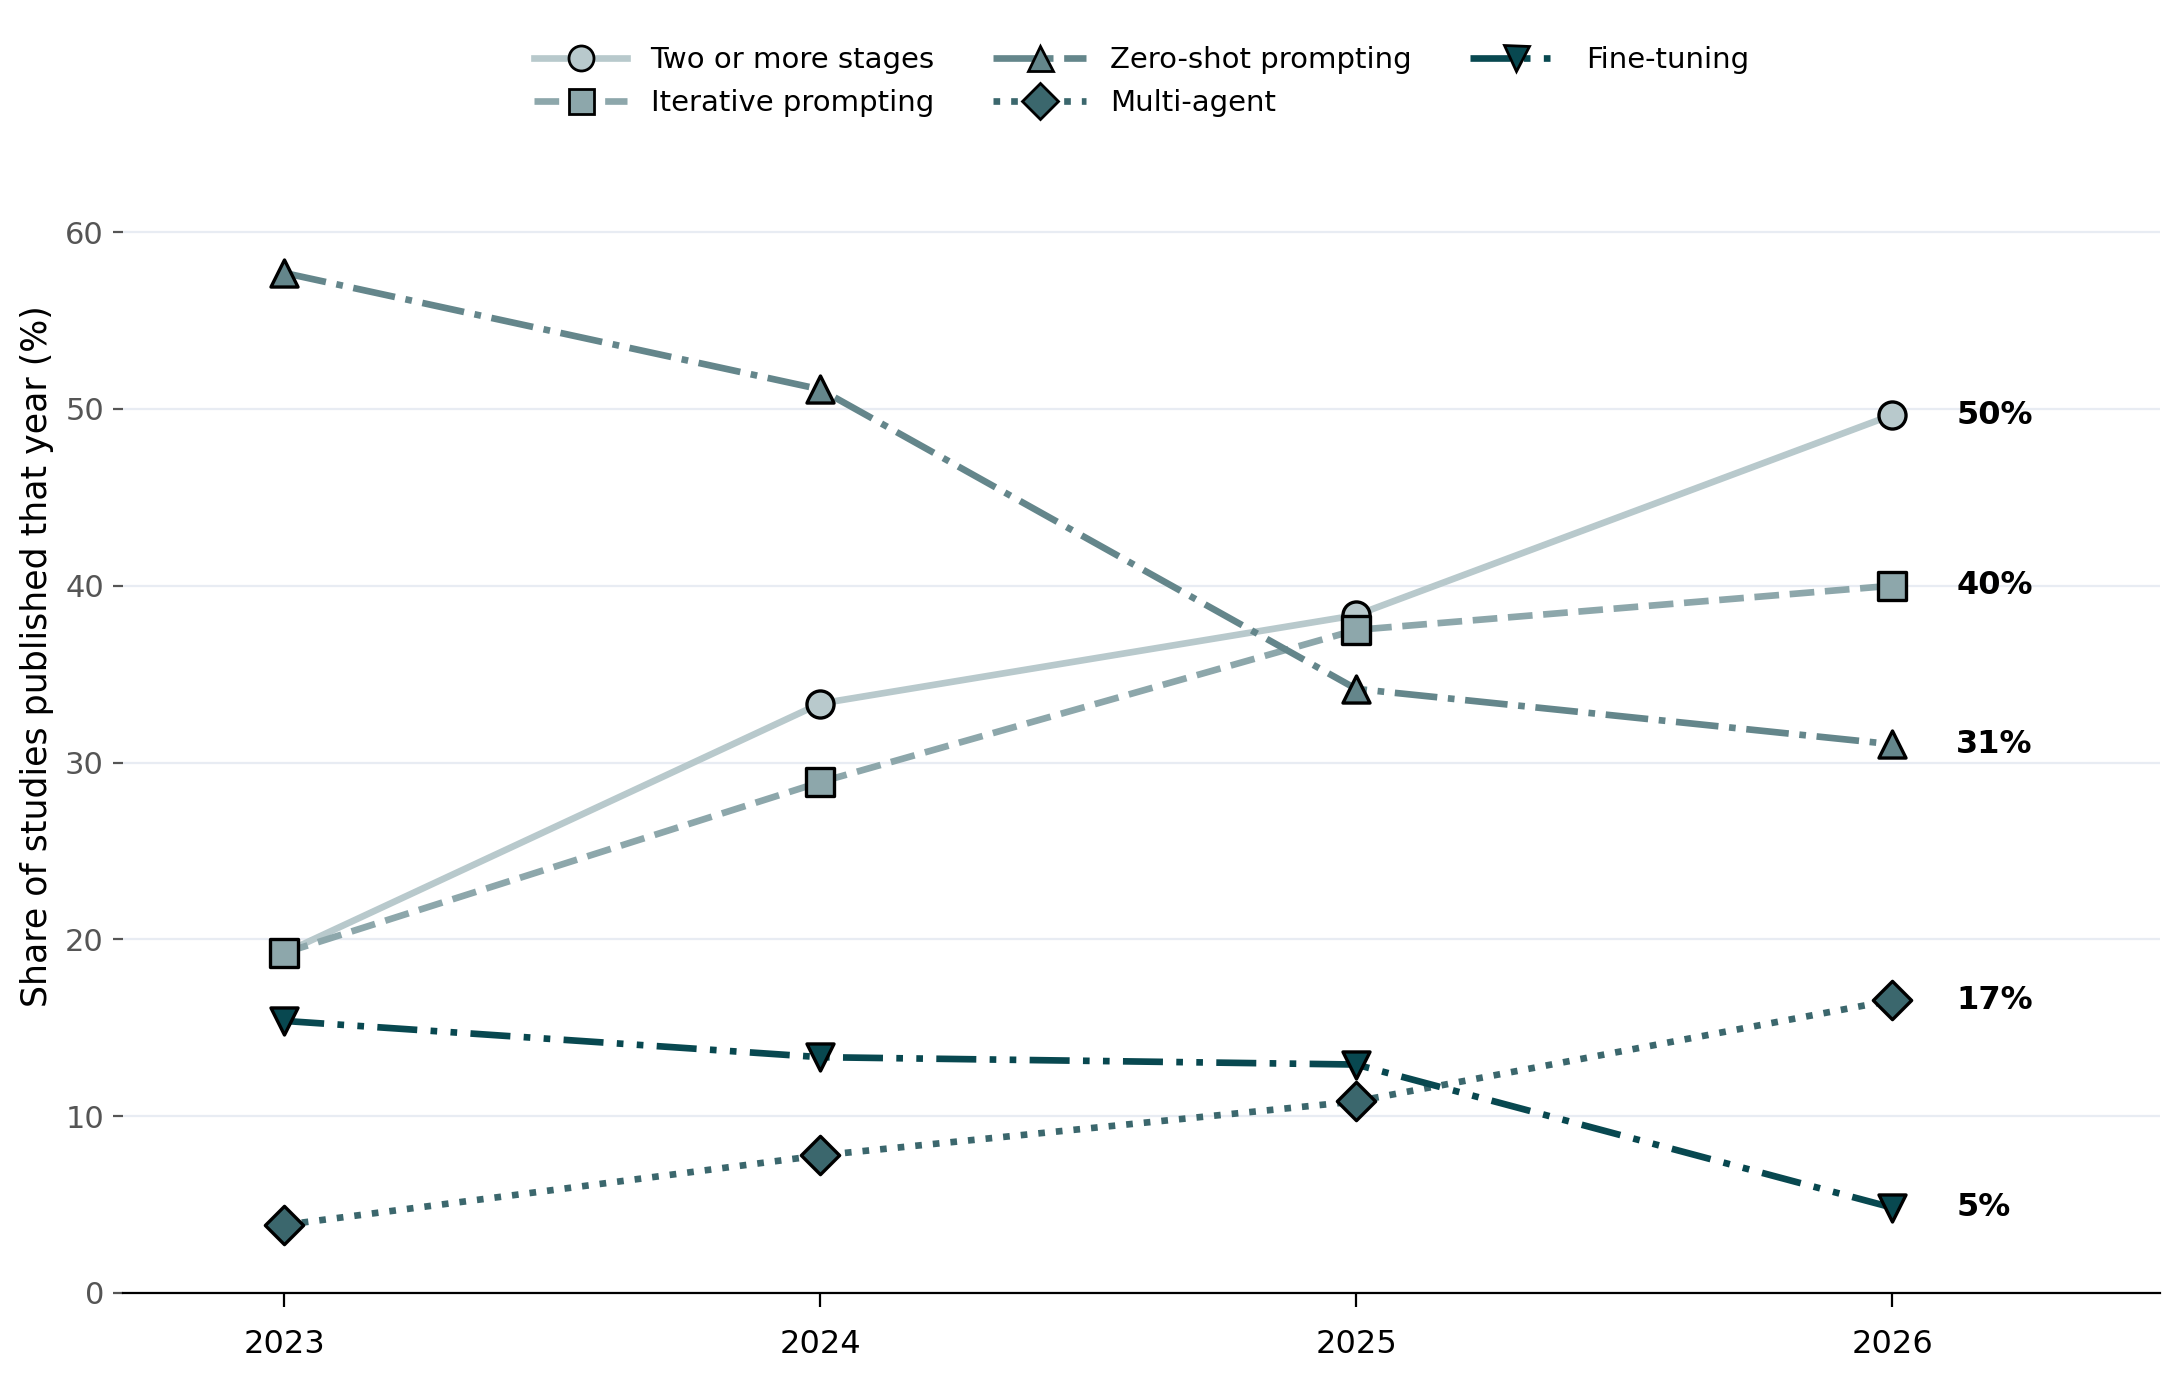

In [3]:
# estudos de cada ano que usam a técnica (dados_jss.tendencias)
print({k: sum(v) for k, v in tendencias.items()})
print("Multi-agent: a coluna Architecture está vazia em", SEM_ARQUITETURA, "estudos, que não contam como multiagente")

fig, ax = grafico_linhas(
    tendencias,
    ylabel="Share of studies published that year (%)",
    ylim=(0, 72),
    rotulo_final=lambda nome, pct: f"{pct:.0f}%",
    espaco_rotulos=3.5,
    xmax_extra=0.5,
    cores=CINZAS_LINHA[::-1],   # começa pela cor mais clara
)
ax.set_yticks(range(0, 61, 10))

plt.tight_layout()
plt.savefig("jss_trends.pdf", bbox_inches="tight")
plt.savefig("jss_trends.png", bbox_inches="tight", dpi=200)
plt.show()

## Propósito do código × loop — `images/jss_code_purpose_loop.pdf`

{'Unit testing': 139, 'Other (fuzz drivers, compilers, ...)': 45, 'E2E testing': 26, 'Acceptance testing': 18, 'Mutation': 15, 'Bug reproduction': 12, 'Security / vulnerability': 11, 'API testing': 8, 'Training data': 1}


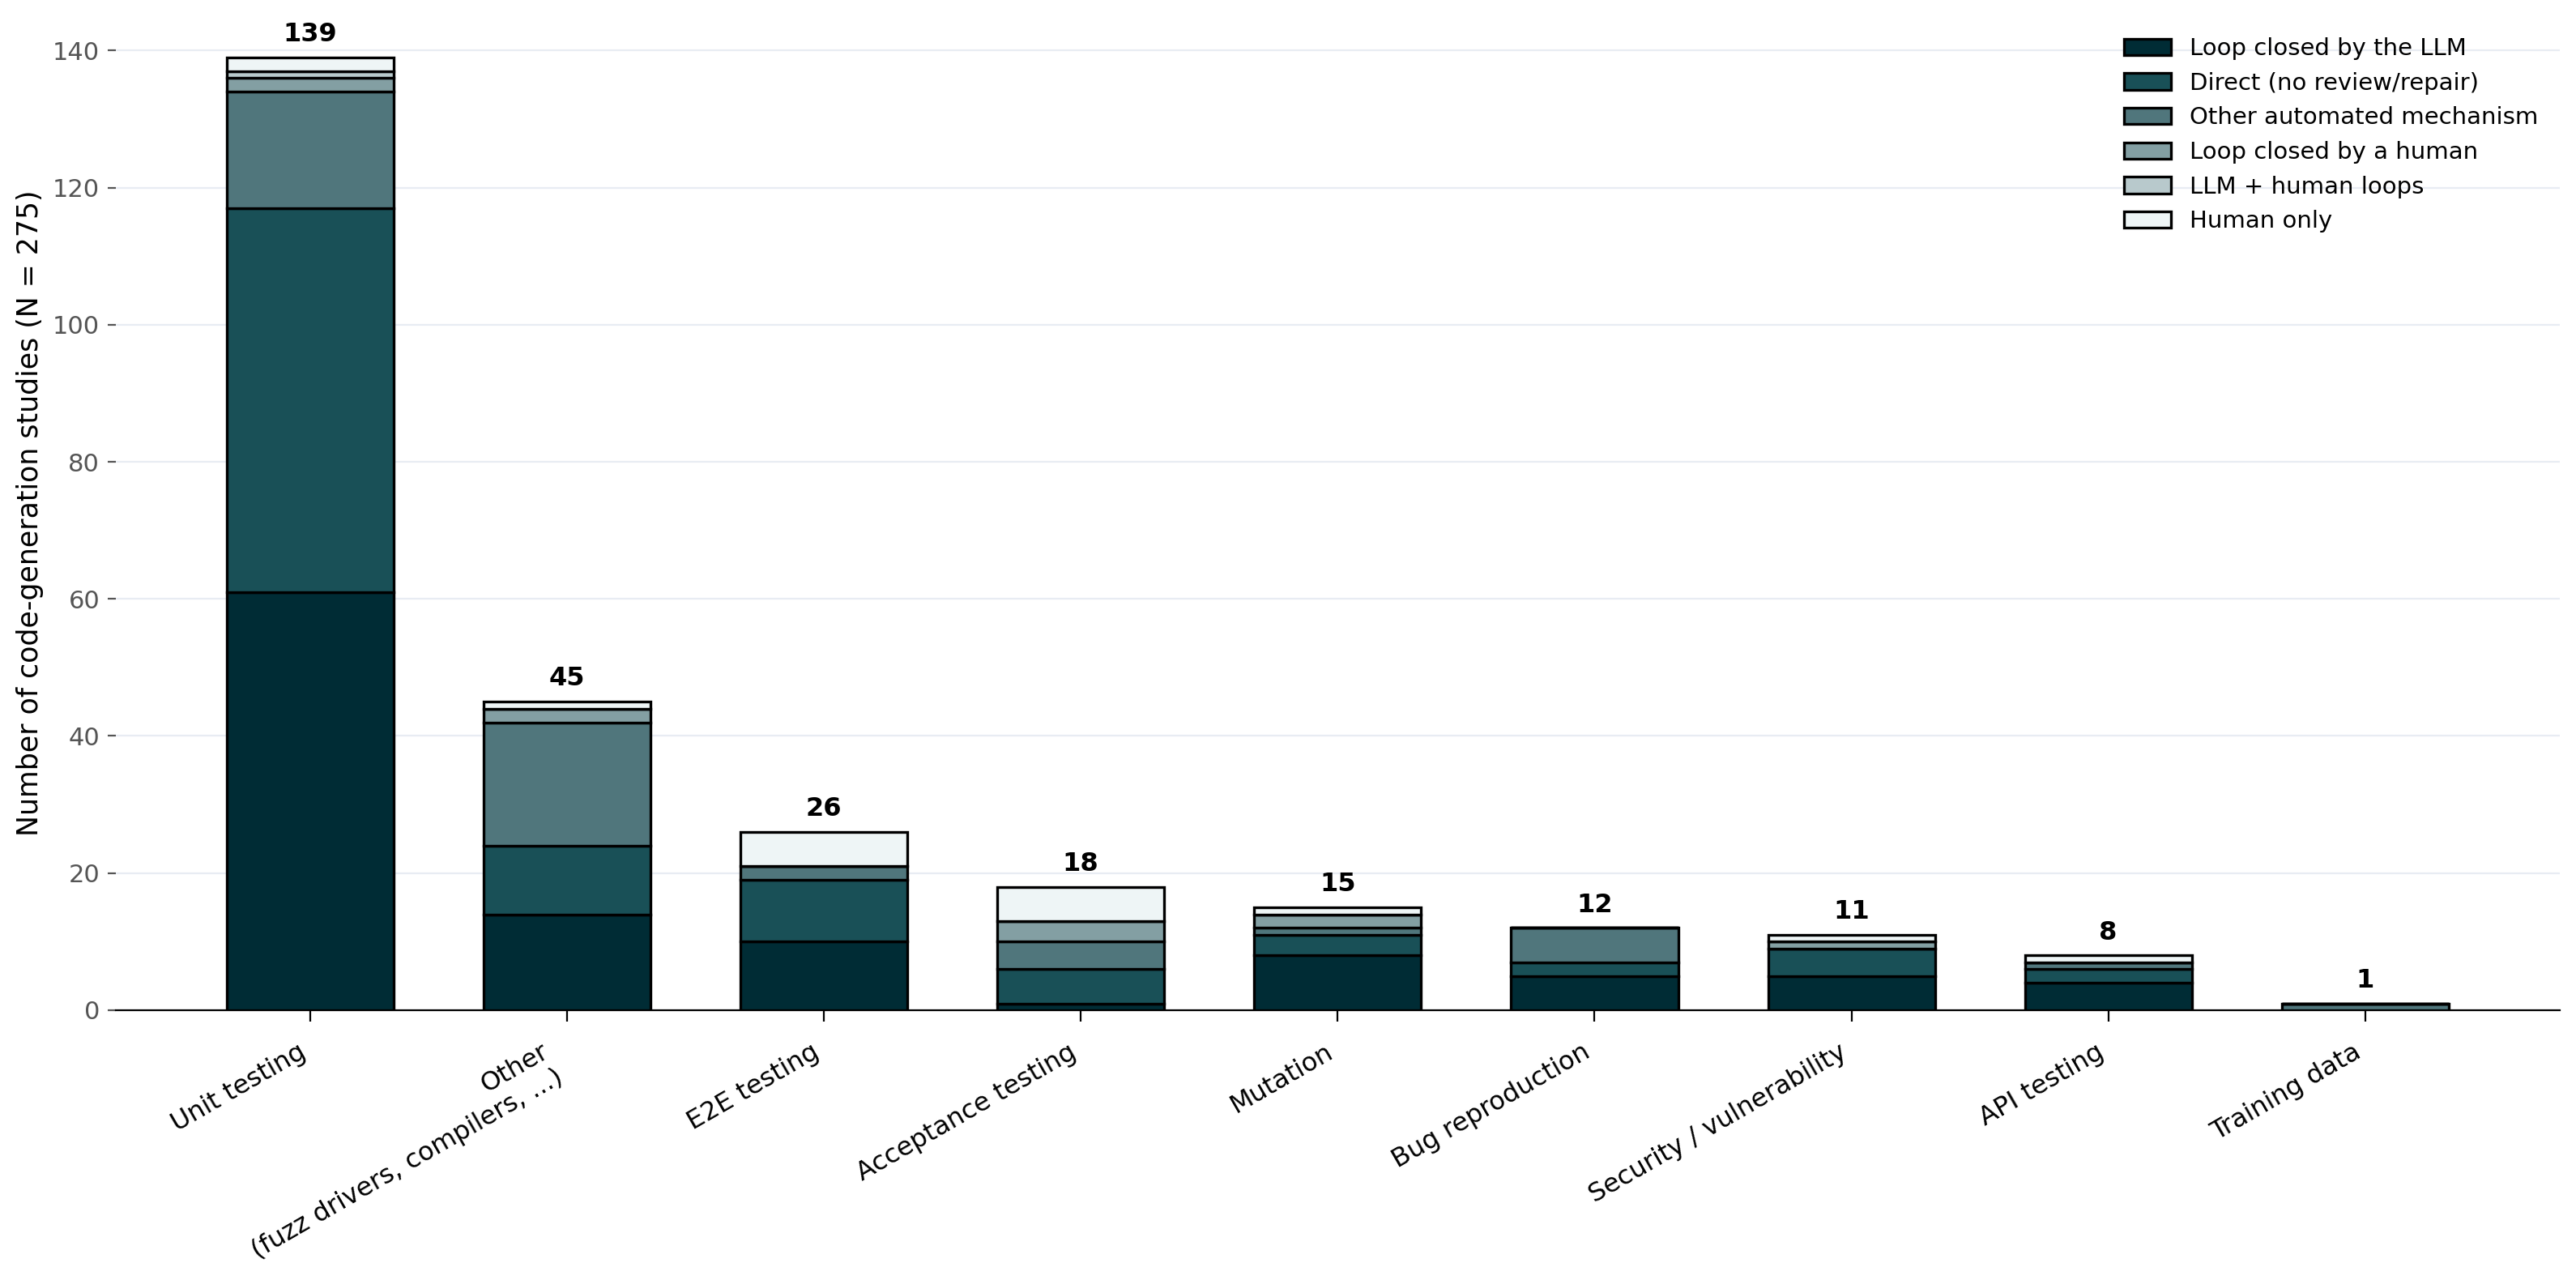

In [4]:
# propósito do código x loop (dados_jss.propositos; mesmos dados de ../code/grafico_tipo_codigo.ipynb)
print({k: sum(v) for k, v in propositos.items()})

fig, ax = plt.subplots(figsize=(16, 8), dpi=200)
nomes = list(propositos)
x_pos = np.arange(len(nomes))
base = np.zeros(len(nomes))
for j, caminho in enumerate(caminhos):
    vals = np.array([propositos[n][j] for n in nomes])
    ax.bar(x_pos, vals, bottom=base, color=CINZAS[j], width=0.65,
           edgecolor="black", linewidth=1.2, zorder=3)
    base += vals
for x, total in zip(x_pos, base):
    ax.text(x, total + 1.5, str(int(total)), ha="center", va="bottom",
            fontsize=11.5, fontweight="bold", color=COR_VALOR)

ax.set_xticks(list(x_pos))
ax.set_xticklabels([n.replace(" (", "\n(") for n in nomes], rotation=30, ha="right", fontsize=10.5)
ax.set_ylim(0, 145)
estilo_atividades(ax, f"Number of code-generation studies (N = {int(base.sum())})")

legend_handles = [
    Patch(facecolor=CINZAS[j], edgecolor="black", linewidth=1.2, label=c)
    for j, c in enumerate(caminhos)
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=10.5)

plt.tight_layout()
plt.savefig("jss_code_purpose_loop.pdf", bbox_inches="tight")
plt.savefig("jss_code_purpose_loop.png", bbox_inches="tight", dpi=200)
plt.show()